# Weak lensing II: shear response in Rubin DP2

In Notebook 1 we saw that the shape we measure is not the shear we want: the PSF rounds galaxies, noise biases faint ones, and shear changes which galaxies are detected. The **shear response** $R$ summarises all of this:

$$
\langle e_i \rangle \approx R_{ij}\, g_j \quad\Rightarrow\quad \hat g = R^{-1} \langle e \rangle .
$$

Here we measure $R$ on the Rubin **Data Preview 2** shear catalog, `dp2.ShearObject`, and see how it depends on galaxy brightness (and, as an exercise, on other properties).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import response_utils as ru
import lensing_utils as lu

## 1. Metadetection

Each image is re-made with a small extra shear of $\pm 0.01$, and detection and measurement are run again on every copy. This gives five catalogs: `ns` (no extra shear, used for science), `1p`/`1m` ($g_1 = \pm 0.01$) and `2p`/`2m` ($g_2 = \pm 0.01$). The response is a finite difference:

$$
R_{11} = \frac{\langle e_1\rangle_{1p} - \langle e_1\rangle_{1m}}{0.02}, \qquad
R_{22} = \frac{\langle e_2\rangle_{2p} - \langle e_2\rangle_{2m}}{0.02}.
$$

Because each catalog is detected and selected on its own, $R$ also captures how shear changes the selection. Below, one simulated galaxy: the extra shear is invisible by eye but shows up in the measured shape.

R11 for this galaxy = 0.601 (simple moments, no PSF correction)


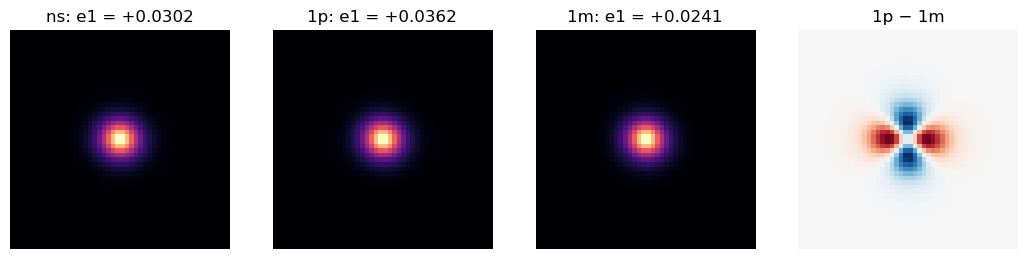

In [2]:
gal = lu.make_galaxy(hlr=0.6, e1=0.1, e2=-0.05)
images = {name: lu.draw(gal.shear(g1=g1, g2=0)) for name, g1 in [('ns', 0), ('1p', 0.01), ('1m', -0.01)]}
e1 = {name: lu.measure_shape(img)['g1'] for name, img in images.items()}

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, name in zip(axes, images):
    ax.imshow(images[name], origin='lower', cmap='magma')
    ax.set_title(f'{name}: e1 = {e1[name]:+.4f}'); ax.set_axis_off()
diff = images['1p'] - images['1m']
axes[3].imshow(diff, origin='lower', cmap='RdBu_r', vmin=-abs(diff).max(), vmax=abs(diff).max())
axes[3].set_title('1p − 1m'); axes[3].set_axis_off()
print(f"R11 for this galaxy = {(e1['1p'] - e1['1m']) / 0.02:.3f} (simple moments, no PSF correction)")

## 2. The data

We use galaxies from a circle in the middle of the main DP2 region, about 200,000 per catalog. There are three ways to get them:

1. **The class download (simplest).** Download `dp2_shear_sample.parquet` (and its `.json`) from the course repository into the folder `DATA_DIR`. No account needed.
2. **Query DP2 yourself.** Set `RUN_QUERY = True`. This needs a [Rubin Science Platform](https://data.lsst.cloud/) account: on the RSP it works automatically; elsewhere, create a token with the `read:tap` scope ([instructions](https://rsp.lsst.io/guides/auth/creating-user-tokens.html)) and put it in the environment variable `RSP_TOKEN`. The result is saved in `DATA_DIR` under the same name.
3. **No data at all.** The notebook falls back to a small simulated (mock) catalog.

The query applies the whole galaxy selection on the server:

* good measurements: `gauss_flags = 0`, masked fraction `mfrac < 0.1`;
* S/N > 10, and larger than the PSF, $T > 0.5\,T_{\rm PSF}$ (removes stars);
* $T < 20$ arcsec² and $19 < i < 23.5$ (removes bright stars and very faint objects).

Cutting in the query is allowed because each row is one object on *one* sheared image, so each catalog is cut on its own measurements.

In [3]:
DATA_DIR = './'           # folder with the class download, dp2_shear_sample.parquet
RUN_QUERY = False           # True: query DP2 yourself (needs an RSP token); saved in DATA_DIR
USE_MOCK = False            # True: use the simulated catalog instead

# the query settings (used when RUN_QUERY = True; CUTS is also applied to a local download)
RA, DEC = 345.0, -8.18      # degrees: middle of the main DP2 coadd region, Galactic latitude -57°
N_TARGET = 200_000          # selected galaxies wanted in the 'ns' catalog (about 5x as many rows)
CUTS = dict(snr_min=10, tratio_min=0.5, mfrac_max=0.1, T_max=20, imag_min=19, imag_max=23.5)

df, source, query = ru.load_catalog(DATA_DIR, RUN_QUERY, RA, DEC, N_TARGET, CUTS, use_mock=USE_MOCK)
print(f'{source}: {len(df):,} rows\n')
print(query or '')

local download (./dp2_shear_sample.parquet): 1,049,250 rows

SELECT metaStep, ra, dec, gauss_g1, gauss_g2, gauss_T, gauss_snr, gauss_psfReconvolved_T, psfOriginal_T, i_gaussFlux
FROM dp2.ShearObject
WHERE CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', 345.0, -8.18, 1.649)) = 1
  AND is_primary = 1
  AND gauss_flags = 0
  AND mfrac < 0.1
  AND gauss_snr > 10
  AND gauss_T > 0.5 * gauss_psfReconvolved_T
  AND gauss_T < 20
  AND i_gaussFlux > 1445.4
  AND i_gaussFlux < 91201.1
  AND gauss_g1 IS NOT NULL
  AND gauss_g2 IS NOT NULL


## 3. A first look

galaxies per catalog: {'ns': 209901, '1p': 209971, '1m': 209720, '2p': 209713, '2m': 209945}


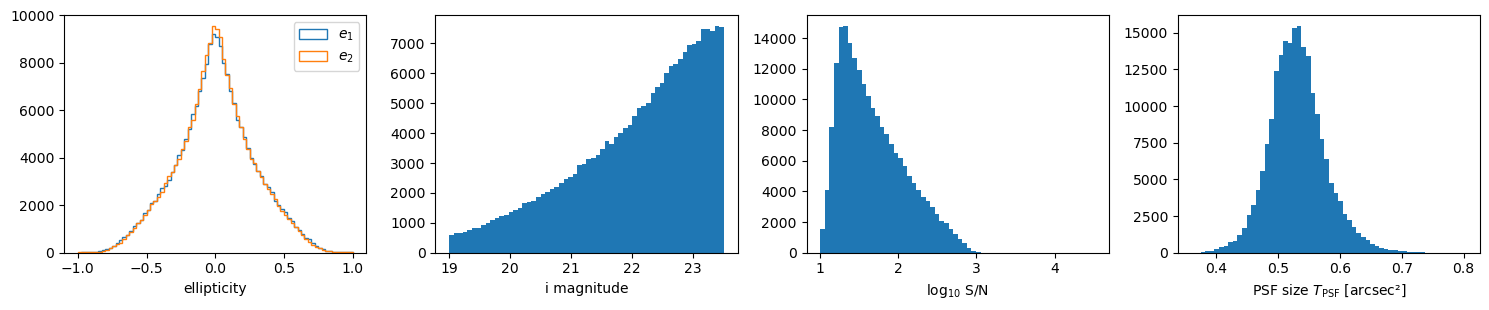

In [4]:
cats = ru.split_steps(df)
print('galaxies per catalog:', {s: len(c) for s, c in cats.items()})

ns = cats['ns']
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
axes[0].hist(ns['gauss_g1'], bins=np.linspace(-1, 1, 81), histtype='step', label='$e_1$')
axes[0].hist(ns['gauss_g2'], bins=np.linspace(-1, 1, 81), histtype='step', label='$e_2$')
axes[0].set_xlabel('ellipticity'); axes[0].legend()
axes[1].hist(ns['i_mag'], bins=60); axes[1].set_xlabel('i magnitude')
axes[2].hist(np.log10(ns['gauss_snr']), bins=60); axes[2].set_xlabel('log$_{10}$ S/N')
axes[3].hist(ns['psfOriginal_T'], bins=60); axes[3].set_xlabel('PSF size $T_{\\rm PSF}$ [arcsec²]')
fig.tight_layout()

The five catalogs have slightly different sizes: a galaxy near a cut can pass in one sheared image and fail in another.

## 4. The response

The mean ellipticity in each sheared catalog, against the extra shear applied: the slope is the response.

R =
 [[0.853 0.007]
 [0.012 0.752]] 
± (jackknife)
 [[0.017 0.014]
 [0.018 0.016]]

raw <e>             = [0.00194 0.00104]
calibrated R^-1 <e> = [0.00226 0.00135]


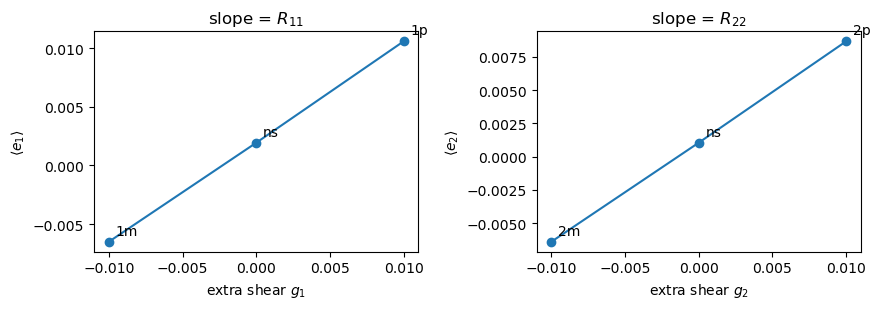

In [5]:
means = {s: (c['gauss_g1'].mean(), c['gauss_g2'].mean()) for s, c in cats.items()}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for i, (ax, steps) in enumerate(zip(axes, [['1m', 'ns', '1p'], ['2m', 'ns', '2p']])):
    ax.plot([-0.01, 0, 0.01], [means[s][i] for s in steps], 'o-')
    for x, s in zip([-0.01, 0, 0.01], steps):
        ax.annotate(s, (x, means[s][i]), textcoords='offset points', xytext=(5, 5))
    ax.set_xlabel(f'extra shear $g_{i + 1}$'); ax.set_ylabel(f'$\\langle e_{i + 1} \\rangle$')
    ax.set_title(f'slope = $R_{{{i + 1}{i + 1}}}$')
fig.tight_layout()

R, R_err = ru.response_with_errors(cats)
e_mean = np.array(means['ns'])
print('R =\n', R.round(3), '\n± (jackknife)\n', R_err.round(3))
print('\nraw <e>             =', e_mean.round(5))
print('calibrated R^-1 <e> =', np.linalg.solve(R, e_mean).round(5))

The DP2 shapes come from fitting each galaxy with a PSF-blurred Gaussian, which removes most of the PSF dilution, so $R$ is not far from 1. What remains (noise, the galaxy model, selection) is what $R$ corrects, and it matters: cosmic shear needs errors well below 1%. $R_{11}$ and $R_{22}$ need not be equal, which is why we calibrate with the full matrix. (The mock uses simple moments without PSF correction, so its $R$ is about 0.6.)

## 5. Response versus brightness

Fainter galaxies have noisier shapes, so we expect $R$ to drop for faint galaxies. `response_vs` splits the galaxies into bins of any column (equal numbers per bin; each sheared catalog is binned on its own measured value) and plots $R_{11}$ and $R_{22}$.

,lo,hi,mid,n,R11,R22,R11_err,R22_err,R,R_err
0,19.000,21.122,20.423,41980,0.846,0.837,0.028,0.020,0.841,0.017
1,21.122,22.003,21.608,41980,0.930,0.876,0.026,0.028,0.903,0.019
2,22.003,22.603,22.326,41980,0.958,0.829,0.052,0.036,0.893,0.032
3,22.603,23.078,22.850,41980,0.796,0.701,0.050,0.038,0.749,0.031
4,23.078,23.500,23.291,41980,0.738,0.521,0.053,0.057,0.630,0.039


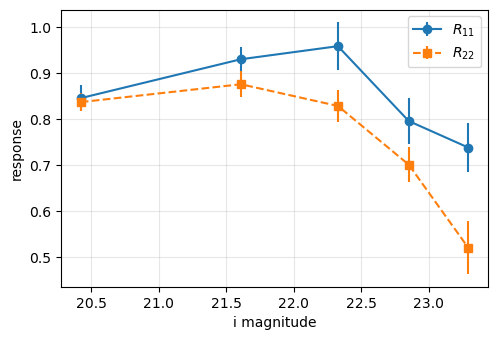

In [6]:
def response_vs(cats, column, label, nbin=5, logx=False, ax=None):
    # equal-number bins from the 'ns' catalog; each sheared catalog is binned on its own value
    edges = np.quantile(cats['ns'][column], np.linspace(0, 1, nbin + 1))
    table = ru.response_in_bins(cats, column, edges)
    ax = ax or plt.subplots(figsize=(5.5, 3.6))[1]
    ax.errorbar(table['mid'], table['R11'], table['R11_err'], marker='o', label='$R_{11}$')
    ax.errorbar(table['mid'], table['R22'], table['R22_err'], marker='s', ls='--', label='$R_{22}$')
    ax.set_xlabel(label); ax.set_ylabel('response'); ax.grid(alpha=0.3); ax.legend()
    if logx:
        ax.set_xscale('log')
        ax.xaxis.set_minor_formatter(plt.NullFormatter())   # keep only the 10, 100, ... labels
    return table

response_vs(cats, 'i_mag', 'i magnitude').round(3)

## 6. Response versus other properties

`response_vs` works for any column of the catalog. For example, the PSF size: a larger PSF rounds small galaxies more, so we might expect $R$ to drop as $T_{\rm PSF}$ grows.

,lo,hi,mid,n,R11,R22,R11_err,R22_err,R,R_err
0,0.360,0.496,0.478,41975,0.912,0.698,0.028,0.031,0.805,0.021
1,0.496,0.519,0.508,41984,0.851,0.774,0.040,0.033,0.812,0.026
2,0.519,0.539,0.529,41980,0.847,0.808,0.032,0.030,0.828,0.022
3,0.539,0.565,0.551,41981,0.844,0.752,0.048,0.046,0.798,0.033
4,0.565,0.804,0.588,41977,0.813,0.730,0.042,0.035,0.772,0.027


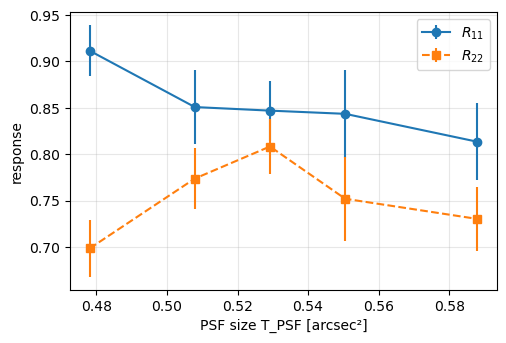

In [7]:
response_vs(cats, 'psfOriginal_T', 'PSF size T_PSF [arcsec²]').round(3)

**Exercise.** Make the same plot for other properties. Pick a column from the table, set `COLUMN` and `LABEL` below, and run the cell. Predict each trend before you plot it.

| column | property | log axis? |
|---|---|---|
| `gauss_snr` | signal-to-noise | yes |
| `T_ratio` | galaxy size relative to the PSF, $T / T_{\rm PSF}$ | yes |
| `gauss_T` | galaxy size $T$ [arcsec²] | yes |
| `i_mag` | $i$-band magnitude | no |
| `psfOriginal_T` | PSF size $T_{\rm PSF}$ [arcsec²] | no |

Which property is $R$ most sensitive to? Do $R_{11}$ and $R_{22}$ follow the same trends?

,lo,hi,mid,n,R11,R22,R11_err,R22_err,R,R_err
0,10.002,19.849,16.285,41980,0.571,0.486,0.041,0.057,0.529,0.035
1,19.849,30.072,24.142,41980,0.759,0.674,0.044,0.045,0.716,0.032
2,30.072,51.552,38.595,41981,0.987,0.837,0.031,0.035,0.912,0.023
3,51.552,110.295,72.533,41979,0.878,0.905,0.037,0.022,0.892,0.022
4,110.295,33016.602,197.706,41980,1.074,0.862,0.033,0.023,0.968,0.020


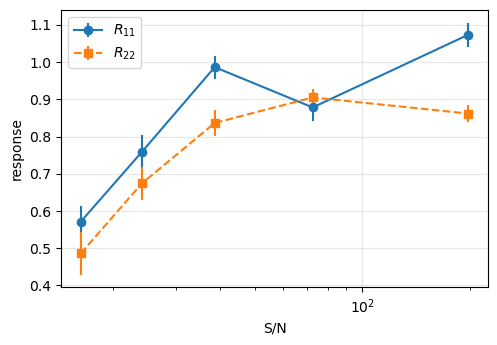

In [8]:
COLUMN = 'gauss_snr'        # a column name from the table
LABEL = 'S/N'               # text for the x axis
LOG = True                  # log x axis?

response_vs(cats, COLUMN, LABEL, logx=LOG).round(3)

## Summary and questions

* Metadetection measures the response from the data by re-measuring sheared copies of every image.
* $R$ depends on galaxy properties (such as S/N and brightness) and on the selection, so it is measured for exactly the sample used; the calibrated shear is $\hat g = R^{-1}\langle e\rangle$.